# Explainable Machine Learning for Childhood Stunting Prediction in Bangladesh

## Project Overview

This project develops an explainable machine learning framework to predict childhood stunting among under-five children in Bangladesh using Bangladesh Demographic and Health Survey (BDHS) data.

The workflow combines:
- Epidemiological analysis
- Machine learning models
- Explainable AI (SHAP)

The objective is to identify important child, maternal, and socioeconomic factors associated with childhood stunting.

**Dataset:** Bangladesh Demographic and Health Survey (BDHS) Children's Recode Dataset


# Import Libraries

In [10]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)

from sklearn.calibration import calibration_curve

import shap

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42


# Load Dataset

Upload the BDHS Children's Recode file (`BDKR81FL.DTA`) before running this section.

In [11]:
from google.colab import files
import zipfile
import os
import glob
import pandas as pd

# Upload ZIP file containing BDKR81FL.DTA
uploaded = files.upload()

# Get uploaded zip filename
zip_file = list(uploaded.keys())[0]

# Extract ZIP
with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("dataset")

# Find .DTA file automatically
dta_files = glob.glob("dataset/**/*.DTA", recursive=True)

if len(dta_files) == 0:
    raise FileNotFoundError("No .DTA file found inside ZIP")

dta_path = dta_files[0]

print("Dataset found:", dta_path)

# Load DHS dataset
df = pd.read_stata(dta_path)

print("Dataset shape:", df.shape)

df.head()

Saving BDHS Data.zip to BDHS Data (3).zip
Dataset found: dataset/BDIR81DT/BDIR81FL.DTA
Dataset shape: (30078, 5425)


,caseid,v000,v001,v002,v003,v004,v005,v006,v007,v008,...,s631j_3,s631j_4,s631j_5,s631j_6,s631k_1,s631k_2,s631k_3,s631k_4,s631k_5,s631k_6
0,1 1 3,BD8,1,1,3,1,156207,9,2022,1473,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1 4 2,BD8,1,4,2,1,156207,9,2022,1473,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1 7 3,BD8,1,7,3,1,156207,9,2022,1473,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1 10 2,BD8,1,10,2,1,156207,9,2022,1473,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1 13 2,BD8,1,13,2,1,156207,9,2022,1473,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Define Stunting Outcome

Stunting was defined using DHS height-for-age z-score (HW70).

- HAZ < -2 SD: Stunted
- HAZ >= -2 SD: Not stunted

In [14]:
import numpy as np
import pandas as pd
import glob
kr_files = glob.glob("dataset/**/*KR*.DTA", recursive=True)
if kr_files:
    print(f"Correcting dataset: Loading Children's Recode from {kr_files[0]}")
    df = pd.read_stata(kr_files[0])
else:
    print("Warning: BDKR81FL.DTA not found in dataset folder. Using existing df.")

# Define stunting using height-for-age z-score (hw70)
df['stunting'] = np.nan

df.loc[df['hw70'] < -200, 'stunting'] = 1
df.loc[df['hw70'] >= -200, 'stunting'] = 0

data = df[df['stunting'].notna()].copy()

print("Data shape:", data.shape)
print("Stunting distribution (%):")
print(data['stunting'].value_counts(normalize=True) * 100)

Correcting dataset: Loading Children's Recode from dataset/BDKR81DT/BDKR81FL.DTA
Data shape: (4118, 1239)
Stunting distribution (%):
stunting
0.0    76.542011
1.0    23.457989
Name: proportion, dtype: float64


# Data Preparation

In [15]:
features = [
    'b4',
    'bord',
    'v012',
    'v106',
    'v437',
    'v190',
    'v025',
    'v024',
    'v113',
    'v116',
    'hw1'
]

ml_data = data[features + ['stunting']].copy()

ml_data['v437'] = pd.to_numeric(
    ml_data['v437'],
    errors='coerce'
)

ml_data['mother_weight_kg'] = ml_data['v437']/10

ml_data.drop(
    'v437',
    axis=1,
    inplace=True
)

ml_data.rename(
    columns={'hw1':'child_age_months'},
    inplace=True
)

ml_data['mother_weight_kg'] = ml_data['mother_weight_kg'].fillna(
    ml_data['mother_weight_kg'].median()
)

ml_data.head()


,b4,bord,v012,v106,v190,v025,v024,v113,v116,child_age_months,stunting,mother_weight_kg
2,male,1,22,secondary,richest,urban,barishal,piped into dwelling,flush to piped sewer system,46.0,0.0,57.4
4,male,1,21,secondary,middle,urban,barishal,tube well or borehole,flush to septic tank,46.0,0.0,74.9
5,male,3,32,higher,richest,urban,barishal,tube well or borehole,flush to septic tank,49.0,0.0,61.7
6,male,2,26,higher,richer,urban,barishal,tube well or borehole,flush to pit latrine,32.0,0.0,52.2
9,male,2,25,secondary,richer,urban,barishal,tube well or borehole,flush to somewhere else,18.0,0.0,63.1


# Train-Test Split and Preprocessing

In [16]:
X = ml_data.drop('stunting', axis=1)
y = ml_data['stunting']

categorical_cols = [
    'b4',
    'v106',
    'v190',
    'v025',
    'v024',
    'v113',
    'v116'
]

numeric_cols = [
    'bord',
    'v012',
    'mother_weight_kg',
    'child_age_months'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', StandardScaler(), numeric_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)


# Model Development

In [17]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        random_state=RANDOM_STATE
    )
}

trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)

    trained_models[name] = pipe
    predictions[name] = pipe.predict(X_test)
    probabilities[name] = pipe.predict_proba(X_test)[:,1]


# Model Evaluation

In [18]:
results = []

for name in models.keys():
    results.append([
        name,
        accuracy_score(y_test, predictions[name]),
        precision_score(y_test, predictions[name]),
        recall_score(y_test, predictions[name]),
        f1_score(y_test, predictions[name]),
        roc_auc_score(y_test, probabilities[name])
    ])

performance = pd.DataFrame(
    results,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score',
        'ROC-AUC'
    ]
)

performance


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.614078,0.324930,0.601036,0.421818,0.673050
1,Random Forest,0.762136,0.457143,0.082902,0.140351,0.630121
2,XGBoost,0.743932,0.378378,0.145078,0.209738,0.642126


# ROC Curve

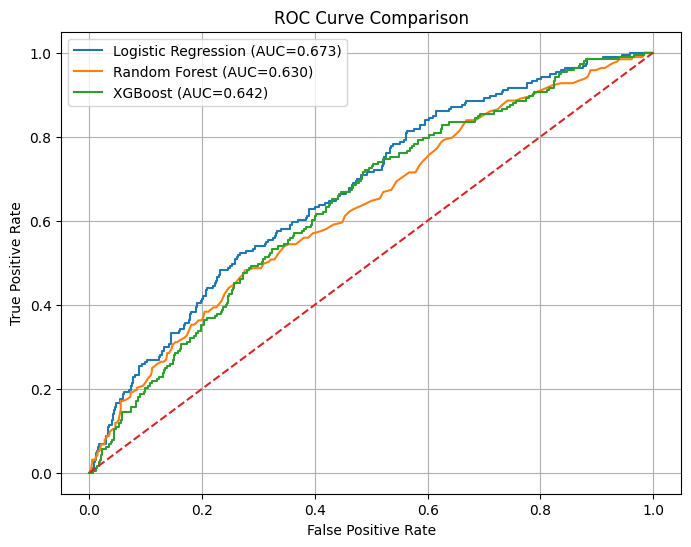

In [19]:
plt.figure(figsize=(8,6))

for name in models.keys():
    fpr, tpr, _ = roc_curve(
        y_test,
        probabilities[name]
    )

    auc = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()


# Threshold Optimization (Logistic Regression)

In [20]:
lr_prob = probabilities["Logistic Regression"]

threshold = 0.40

lr_threshold_pred = (lr_prob >= threshold).astype(int)

print("Recall:", recall_score(y_test, lr_threshold_pred))
print("Precision:", precision_score(y_test, lr_threshold_pred))
print("F1-score:", f1_score(y_test, lr_threshold_pred))

confusion_matrix(y_test, lr_threshold_pred)


Recall: 0.844559585492228
Precision: 0.29744525547445255
F1-score: 0.4399460188933873


array([[246, 385],
       [ 30, 163]])

# Odds Ratio Analysis

In [23]:
or_data = ml_data.copy()

or_data = pd.get_dummies(
    or_data,
    columns=[
        'b4',
        'v106',
        'v190',
        'v025',
        'v024',
        'v113',
        'v116'
    ],
    drop_first=True
)

X_or = sm.add_constant(
    or_data.drop('stunting', axis=1).astype(float)
)

y_or = or_data['stunting']

result = sm.Logit(
    y_or,
    X_or
).fit()

params = result.params
conf = result.conf_int()

odds_ratio = pd.DataFrame({
    "OR": np.exp(params),
    "Lower_CI": np.exp(conf[0]),
    "Upper_CI": np.exp(conf[1]),
    "p_value": result.pvalues
})

odds_ratio.sort_values('OR', ascending=False)

         Current function value: 0.503690
         Iterations: 35


,OR,Lower_CI,Upper_CI,p_value
v113_other,2.058355e+08,0.000000,inf,9.978118e-01
const,5.347103e+00,2.189417,13.058960,2.331893e-04
v113_rainwater,1.700250e+00,0.644857,4.482933,2.832596e-01
v113_bottled water,1.535655e+00,0.587807,4.011921,3.813097e-01
v116_hanging toilet/latrine,1.191920e+00,0.555202,2.558843,6.524207e-01
bord,1.180543e+00,1.073343,1.298450,6.327483e-04
v113_public tap/standpipe,1.153083e+00,0.570515,2.330529,6.915510e-01
v024_sylhet,1.151049e+00,0.850875,1.557119,3.615204e-01
v024_chattogram,1.078624e+00,0.806699,1.442211,6.095884e-01
v116_flush to somewhere else,1.033513e+00,0.494680,2.159271,9.301272e-01


# SHAP Explainability

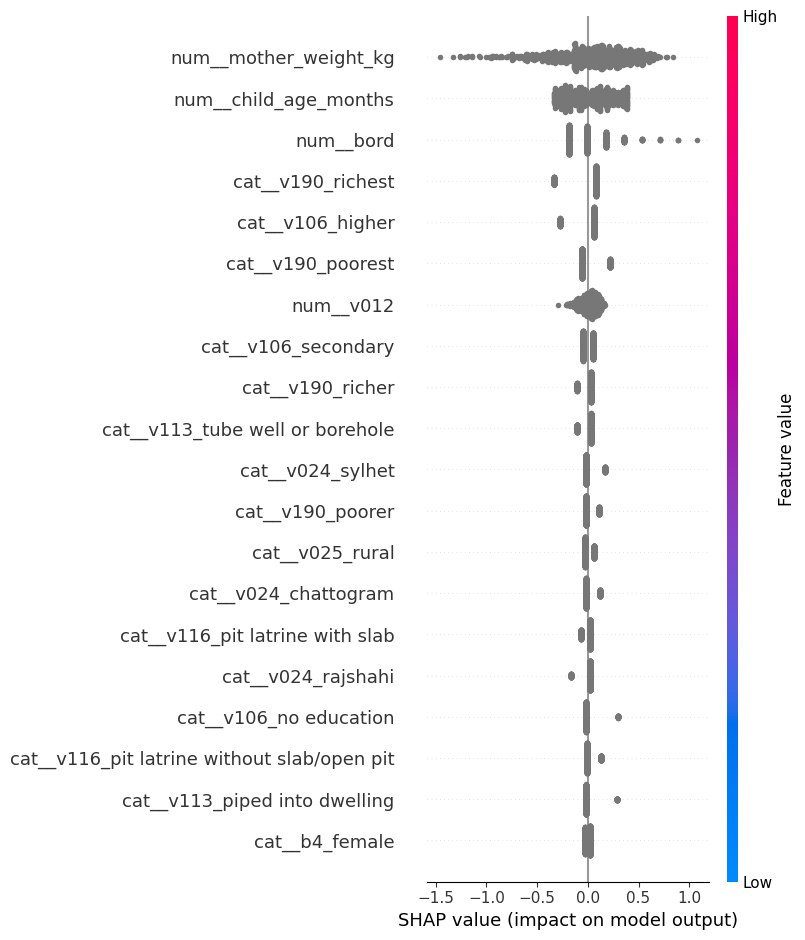

In [24]:
lr_pipeline = trained_models["Logistic Regression"]

preprocessor_fitted = lr_pipeline.named_steps['preprocessor']
lr_model = lr_pipeline.named_steps['model']

X_train_transformed = preprocessor_fitted.transform(X_train)
X_test_transformed = preprocessor_fitted.transform(X_test)

feature_names = preprocessor_fitted.get_feature_names_out()

explainer = shap.LinearExplainer(
    lr_model,
    X_train_transformed
)

shap_values = explainer.shap_values(
    X_test_transformed
)

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names
)


# Key Findings

Main predictors identified:

- Maternal nutritional status
- Child age
- Birth order
- Household wealth
- Maternal education

The logistic regression model showed the strongest discrimination among tested models, while threshold optimization improved sensitivity for screening purposes.

# Conclusion

This project demonstrates how statistical modelling and explainable machine learning can be combined to study childhood stunting risk factors in Bangladesh.
